# Model M1: when to start verifying

M1 extends M0 from one year to 2026–2034. For each installation, the exporter chooses a **start year**, which can be no earlier than its customer's. In the start year it pays a one-off monitoring set-up cost and the first verification. It then learns the installation's emissions and decides once: **use** the verified data every year to 2034 (paying the annual verification cost), or **withhold** it and stay on defaults.

The value of starting node *i* in year *s* is computed from the leaves up:

W<sub>i</sub>(s) = −c<sup>0</sup><sub>i</sub> − c<sub>i</sub> + ρ<sub>i</sub> · E[ max{0, Ā<sub>i</sub>(s) − B̄<sub>i</sub>(s) θ<sub>i</sub>} ]

Here B̄ and Ā add up the yearly M0 terms from *s* to 2034, discounted, plus the best start for each supplier. The root starts in the year with the highest discounted W. The expectation has the same closed form as in M0, so the plan is exact and takes a few milliseconds.

Central assumptions: an 8% discount rate, a set-up cost equal to one year's verification cost, and the futures price path. A failed verification is taken as permanent. Values are present values in 2026 euros relative to staying on defaults throughout.

Baselines:
- **2026 or never**: the same model, but every start must be in 2026;
- **no withholding**: every result is used;
- **start all in 2026**: verify every node from 2026 and use every result.

In [1]:
import subprocess, sys
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 60)
print(subprocess.run([sys.executable, "scripts/run_m1.py"], cwd=ROOT, capture_output=True, text=True, check=True).stdout)
base = pd.read_csv(ROOT / "Data/results/m1_base.csv")
plans = pd.read_csv(ROOT / "Data/results/m1_plans.csv")
sweeps = pd.read_csv(ROOT / "Data/results/m1_sweeps.csv")

M1 solved for 4 trees; 96 sweep runs (discount rate 8%, set-up cost 1 x annual cost)
  T1: PV EUR   50,285,835 | 2026-or-never   50,285,835 | no withholding   50,276,409 | start all 2026   50,276,409 | R:2026 M1:2026 M2:2026
  T2: PV EUR    7,569,267 | 2026-or-never    4,213,099 | no withholding    4,496,794 | start all 2026   -2,265,986 | R:2028 DRI:2028 PEL:2028 PIG:2028
  T3: PV EUR   36,449,122 | 2026-or-never   36,449,122 | no withholding   35,868,776 | start all 2026   35,868,776 | R:2026 EAF:2026 BF:2026
  T4: PV EUR   19,813,056 | 2026-or-never   19,813,056 | no withholding   19,714,066 | start all 2026   19,714,066 | R:2026 PRI:2026 SEC:2026



## 1. Present value of the M1 plan against the alternatives (EUR million, 2026–2034)

In [2]:
t = base.set_index("tree")
money = ["pv_m1", "pv_now_or_never", "pv_no_withholding", "pv_start_all_2026", "value_of_waiting", "value_of_withholding"]
out = (t[money] / 1e6).round(2)
out.columns = ["M1", "2026 or never", "no withholding", "start all 2026", "value of waiting", "value of withholding"]
out["M1 start years"] = t.start_years_m1
out

,M1,2026 or never,no withholding,start all 2026,value of waiting,value of withholding,M1 start years
tree,,,,,,,
T1,50.29,50.29,50.28,50.28,0.00,0.01,R:2026 M1:2026 M2:2026
T2,7.57,4.21,4.50,-2.27,3.36,3.07,R:2028 DRI:2028 PEL:2028 PIG:2028
T3,36.45,36.45,35.87,35.87,0.00,0.58,R:2026 EAF:2026 BF:2026
T4,19.81,19.81,19.71,19.71,0.00,0.10,R:2026 PRI:2026 SEC:2026


- In T2 (India), waiting is worth €3.4 million, 44% of the plan's value. The best plan starts the whole chain in 2028, because verifying earlier would lock in two years in which actual values cost more certificates than defaults. Withholding adds another €3.1 million.
- In T1, T3 and T4 the best plan starts everything in 2026. Defaults there are well above expected actual emissions, so each year of delay is a year of saving lost.
- In T2, starting everything in 2026 and using every result would lose €2.3 million.

## 2. Value of starting in each year

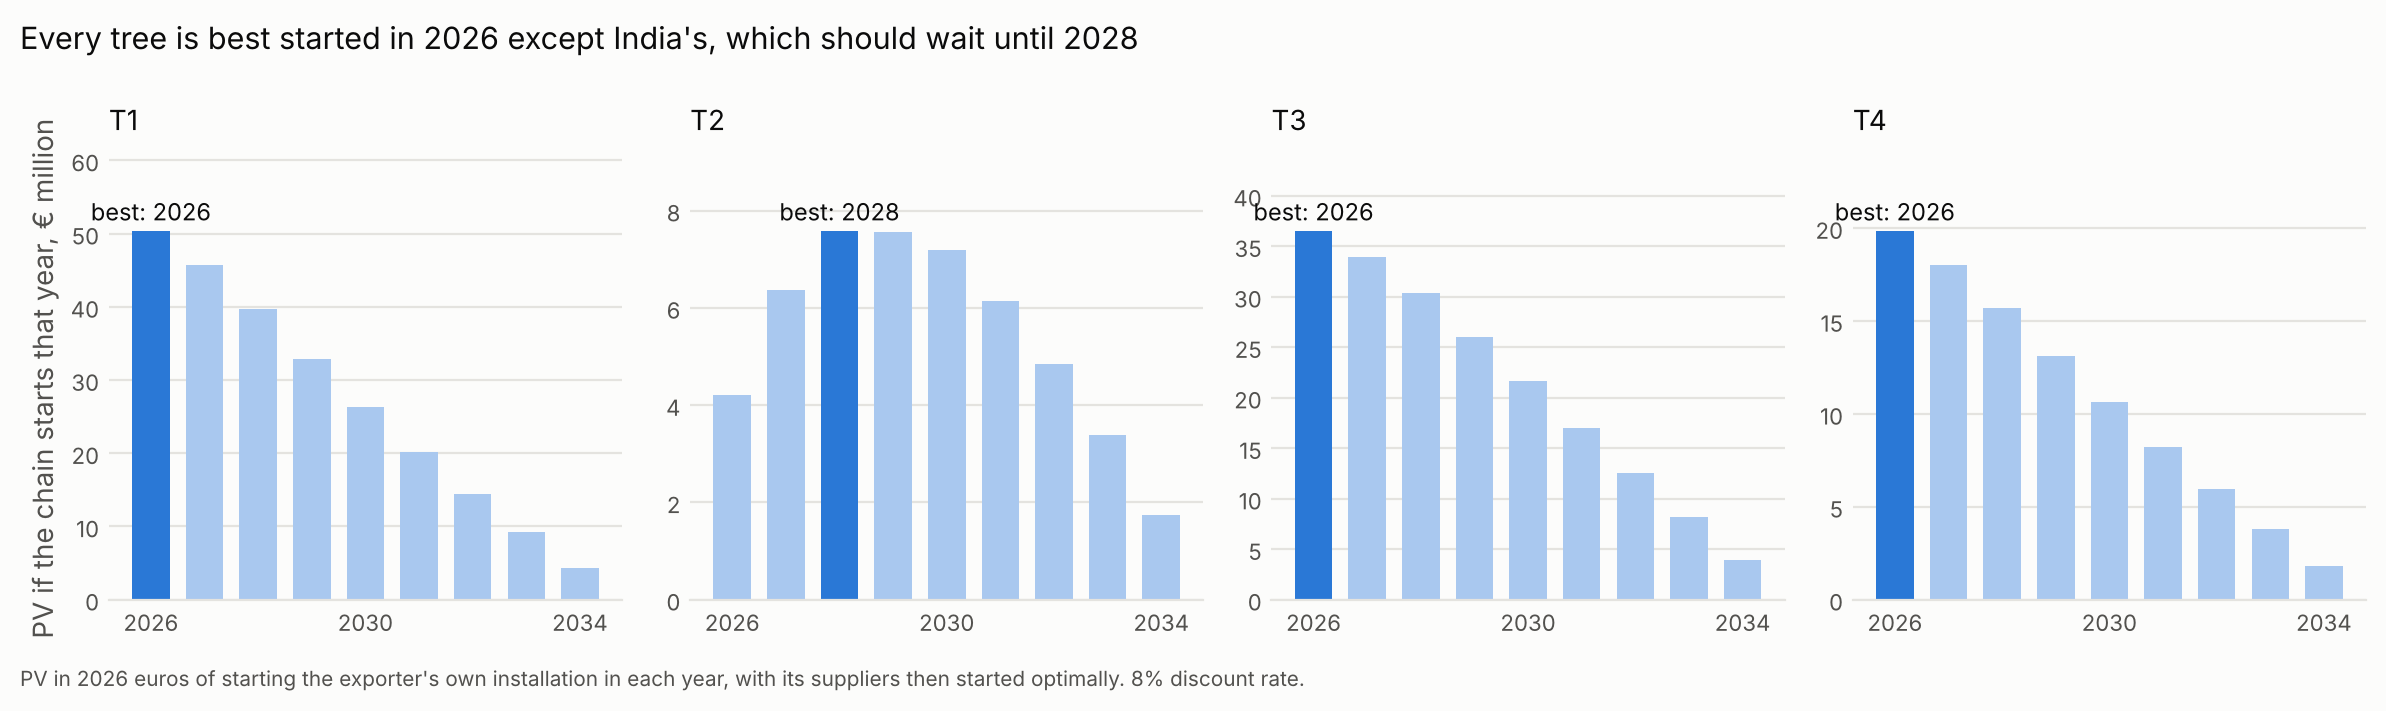

In [3]:
import matplotlib.pyplot as plt

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BAR, BEST = "#a9c8ef", "#2a78d6"
d = 1 / 1.08
years = list(range(2026, 2035))
roots = plans[plans.depth == 0].set_index("tree")

fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), facecolor=SURFACE)
for ax, (tid, r) in zip(axes, roots.iterrows()):
    pv = [max(0.0, d ** (y - 2026) * r[f"W_{y}"]) / 1e6 for y in years]
    best = max(range(len(pv)), key=lambda k: pv[k])
    ax.set_facecolor(SURFACE)
    ax.bar(years, pv, width=0.7, color=[BEST if k == best else BAR for k in range(len(pv))])
    ax.annotate(f"best: {years[best]}", (years[best], pv[best]), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=8.5, color=INK)
    ax.set_title(tid, loc="left", fontsize=10, color=INK, pad=10)
    ax.set_ylim(0, 1.2 * max(pv))
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID); ax.tick_params(colors=INK2, length=0, labelsize=8)
    ax.set_xticks([2026, 2030, 2034])
axes[0].set_ylabel("PV if the chain starts that year, € million", color=INK2)
fig.suptitle("Every tree is best started in 2026 except India's, which should wait until 2028",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.text(0.01, -0.03, "PV in 2026 euros of starting the exporter's own installation in each year, with its suppliers then started optimally. 8% discount rate.",
         fontsize=7.5, color=INK2)
fig.tight_layout(); plt.show()

## 3. What moves the start year in T2 (India)

In [4]:
s2 = sweeps[sweeps.tree == "T2"].copy()
s2["PV € million"] = (s2.pv_m1 / 1e6).round(2)
s2["value of waiting € million"] = (s2.value_of_waiting / 1e6).round(2)
s2[["factor", "level", "start_years", "PV € million", "value of waiting € million"]].set_index(["factor", "level"])

start_years  PV € million  value of waiting € million
factor              level                                                                                
discount_rate       0.0       R:2028 DRI:2028 PEL:2028 PIG:2028         12.21                        3.46
                    0.04      R:2028 DRI:2028 PEL:2028 PIG:2028          9.55                        3.41
                    0.08      R:2028 DRI:2028 PEL:2028 PIG:2028          7.57                        3.36
                    0.15      R:2028 DRI:2028 PEL:2028 PIG:2028          5.17                        3.28
setup_cost_ratio    0.5       R:2028 DRI:2028 PEL:2028 PIG:2028          7.61                        3.35
                    1.0       R:2028 DRI:2028 PEL:2028 PIG:2028          7.57                        3.36
                    2.0       R:2028 DRI:2028 PEL:2028 PIG:2028          7.50                        3.37
                    4.0       R:2029 DRI:2029 PEL:2029 PIG:2029          7.35                        3.39
price_scenario      flat      R:2028 DRI:2028 PEL:2028 PIG:2028          5.83                        3.18
                    futures   R:2028 DRI:2028 PEL:2028 PIG:2028          7.57                        3.36
                    high      R:2028 DRI:2028 PEL:2028 PIG:2028         11.65                        4.12
supplier_cv         0.1       R:2030 DRI:2030 PEL:2030 PIG:2030          4.72                        4.72
                    0.15      R:2030 DRI:2030 PEL:2030 PIG:2030          5.35                        5.10
                    0.25      R:2028 DRI:2028 PEL:2028 PIG:2028          7.57                        3.36
                    0.4       R:2028 DRI:2028 PEL:2028 PIG:2028         12.19                        1.62
volume_t            5000.0    R:2030 DRI:2030 PEL:2030 PIG:2030          0.47                        0.47
                    10000.0   R:2029 DRI:2029 PEL:2029 PIG:2029          1.24                        0.82
                    25000.0   R:2029 DRI:2029 PEL:2029 PIG:2029          3.61                        1.76
                    50000.0   R:2028 DRI:2028 PEL:2028 PIG:2028          7.57                        3.36
                    100000.0  R:2028 DRI:2028 PEL:2028 PIG:2028         15.55                        6.59
                    250000.0  R:2028 DRI:2028 PEL:2028 PIG:2028         39.48                       16.28
success_probability 0.6       R:2030 DRI:2030 PEL:2030 PIG:2030          2.18                        2.18
                    0.9       R:2028 DRI:2028 PEL:2028 PIG:2028          7.57                        3.36
                    1.0       R:2028 DRI:2028 PEL:2028 PIG:2028         10.68                        3.36

Lower volumes, less uncertainty about the suppliers, a lower chance that verification succeeds and a higher set-up cost all push the start later, to 2029 or 2030. More uncertainty brings it to 2028, because the option to withhold is worth more.

## 4. The other trees under the same sweeps

In [5]:
o = sweeps[sweeps.tree != "T2"].copy()
o["PV € million"] = (o.pv_m1 / 1e6).round(2)
o.pivot_table(index=["factor", "level"], columns="tree", values=["PV € million", "start_years"], aggfunc="first")

PV € million                             start_years                                                   
tree                                   T1      T3      T4                      T1                       T3                        T4
factor              level                                                                                                           
discount_rate       0.0             68.86   51.43   27.32  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    0.04            58.41   42.97   23.09  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    0.08            50.29   36.45   19.81  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    0.15            39.94   28.24   15.65  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
price_scenario      flat            40.96   29.35   16.07  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    futures         50.29   36.45   19.81  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    high            76.07   55.52   30.09  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
setup_cost_ratio    0.5             50.39   36.55   19.88  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    1.0             50.29   36.45   19.81  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    2.0             50.08   36.24   19.68  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    4.0             49.66   35.82   19.43  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
success_probability 0.6             21.37   15.79   11.40  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    0.9             50.29   36.45   19.81  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    1.0             62.62   45.22   23.01  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
supplier_cv         0.1             50.28   35.87   19.71  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    0.15            50.28   35.94   19.72  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    0.25            50.29   36.45   19.81  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    0.4             50.62   37.76   20.14  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
volume_t            1000.0            NaN     NaN    1.35                     NaN                      NaN           R:2026 SEC:2026
                    10000.0          8.85    6.13   19.81  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    100000.0       102.08   74.35     NaN  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026                       NaN
                    2000.0            NaN     NaN    3.27                     NaN                      NaN  R:2026 PRI:2027 SEC:2026
                    25000.0         24.39   17.50   50.88  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    250000.0       257.45  188.07     NaN  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026                       NaN
                    5000.0           3.67    2.35    9.46  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026
                    50000.0         50.29   36.45  102.66  R:2026 M1:2026 M2:2026  R:2026 EAF:2026 BF:2026  R:2026 PRI:2026 SEC:2026

In T4 at 2 kt a year, the primary smelter starts a year after the fabricator and the recycled-metal supplier: staggered starts appear when a supplier is only just worth verifying.

## Tests and limitations

- `tests/test_m1.py` checks that M1 equals M0 with one year and no set-up cost, that its value matches an exact evaluation and a simulation of its own plan, that it is never worse than the baselines, and that on every case tree it matches a brute-force search over all start-year assignments (shortened horizon).
- **Use from the start year to 2034.** Once used, a node's data are used every year. A richer model would let the exporter verify early only to *learn* emissions and declare actual values later. That would make early verification more attractive, so the value of waiting is likely to be smaller in that richer model than the figure reported here.
- **Assumptions.** Emissions are constant over time, a failed verification is permanent, and benchmarks after 2027 are the published ones until the update appears.